# Trabajo Práctico: Predicción de lluvia en Australia

**Aprendizaje Automático 1 - Tecnicatura Universitaria en Inteligencia Artificial (FCEIA)**

Integrantes:
* Federico Arias
* Guillermina Bousoño

El objetivo del trabajo es construir y poner en producción un modelo de clasificación binaria capaz de predecir, a las 23:59 hs de cada día, si al día siguiente lloverá o no (`RainTomorrow`) a partir de registros meteorológicos diarios de distintas estaciones de Australia.

---

# 1. Análisis descriptivo y preprocesamiento

## 1.1 Configuración del entorno e inspección inicial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve)



df = pd.read_csv('weatherAUS_2026C2.csv')
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head())
df.info()

c:\Proyectos_tuia\TUIA_AA1_2026\TP1\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dimensiones: 145412 filas x 25 columnas


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

### Descripción de las variables y primer descarte estructural

El dataset releva mediciones diarias (temperaturas, lluvia, viento, humedad, presión y nubosidad medidas a las 9 am y a las 3 pm) junto con la ubicación de la estación (`Location`) y la fecha (`Date`).

Antes de iniciar el análisis estadístico, realizamos tres ajustes estructurales sobre la tabla:
1. **`Unnamed: 0`:** Es una columna de índice redundante generada al exportar el CSV, por lo que se descarta.
2. **Prevención de *Data Leakage* (`RainfallTomorrow`):** La columna `RainfallTomorrow` registra cuántos milímetros llovió efectivamente al día siguiente. Como ese dato ocurre en el futuro respecto del momento de la predicción (23:59 hs del día actual) y determina directamente a `RainTomorrow`, conservarla como predictora provocaría una fuga de información (*data leakage*). Se elimina del conjunto de características.
3. **Filas sin variable objetivo (`RainTomorrow`):** En un problema supervisado no tiene sentido imputar la etiqueta que queremos aprender a predecir, por lo que descartamos los registros donde `RainTomorrow` es nulo (~2.2% del total). También ajustamos el tipo de la columna `Date` a formato fecha (`datetime`).

In [2]:
filas_iniciales = len(df)

# Descarte de índice redundante y de variable con información del futuro (Data Leakage)
cols_descartar = [c for c in ['Unnamed: 0', 'RainfallTomorrow'] if c in df.columns]
df = df.drop(columns=cols_descartar)

# Descarte de filas sin target y conversión de fecha
sin_target = df['RainTomorrow'].isna().sum()
df = df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
df['Date'] = pd.to_datetime(df['Date'])

print(f'Columnas descartadas: {cols_descartar}')
print(f'Filas eliminadas por no tener target (RainTomorrow): {sin_target}')
print(f'Dimensiones del dataset de trabajo: {df.shape[0]} filas x {df.shape[1]} columnas')
print(f'Rango temporal: {df["Date"].min().date()} a {df["Date"].max().date()} ({df["Location"].nunique()} ciudades)')

Columnas descartadas: ['Unnamed: 0', 'RainfallTomorrow']
Filas eliminadas por no tener target (RainTomorrow): 3259
Dimensiones del dataset de trabajo: 142153 filas x 23 columnas
Rango temporal: 2007-11-01 a 2017-06-24 (49 ciudades)


### Descripción de las variables y rangos de variación

| Variable | Tipo | Descripción | Rango de variación |
|----------|------|-------------|--------------------|
| `Date` | Fecha | día de la observación | Fechas del registro temporal |
| `Location` | Categórica nominal | ciudad de la observación | 49 ciudades |
| `MinTemp` | Numérica continua | temperatura mínima del día | -9.7 a 34.1 °C |
| `MaxTemp` | Numérica continua | temperatura máxima del día | -5.1 a 49.1 °C |
| `Rainfall` | Numérica continua | lluvia caída en el día | 0.0 a 371.0 mm |
| `Evaporation` | Numérica continua | evaporación en 24 hs | 0.0 a 145.0 mm |
| `Sunshine` | Numérica continua | horas de sol en el día | 0.0 a 14.5 hs |
| `WindGustDir` | Categórica nominal | dirección de la ráfaga de viento más fuerte | 16 rumbos |
| `WindGustSpeed` | Numérica continua | velocidad de la ráfaga de viento más fuerte | 6.0 a 135.0 km/h |
| `WindDir9am` | Categórica nominal | dirección media del viento a las 9am | 16 rumbos |
| `WindDir3pm` | Categórica nominal | dirección media del viento a las 3pm | 16 rumbos |
| `WindSpeed9am` | Numérica continua | velocidad media del viento a las 9am | 0.0 a 130.0 km/h |
| `WindSpeed3pm` | Numérica continua | velocidad media del viento a las 3pm | 0.0 a 86.0 km/h |
| `Humidity9am` | Numérica continua | humedad relativa a las 9am | 0.0 a 100.0 % |
| `Humidity3pm` | Numérica continua | humedad relativa a las 3pm | 0.0 a 100.0 % |
| `Pressure9am` | Numérica continua | presión atmosférica a las 9am | 980.3 a 1041.2 hPa |
| `Pressure3pm` | Numérica continua | presión atmosférica a las 3pm | 977.4 a 1039.8 hPa |
| `Cloud9am` | Numérica discreta | nubosidad a las 9 am | 0.0 a 9.0 octas |
| `Cloud3pm` | Numérica discreta | nubosidad a las 3 pm | 0.0 a 9.0 octas |
| `Temp9am` | Numérica continua | temperatura a las 9am | -8.0 a 39.8 °C |
| `Temp3pm` | Numérica continua | temperatura a las 3pm | -5.8 a 47.0 °C |
| `RainToday` | Categórica binaria | "Yes" si llovió más de 1 mm en el día | Yes / No |
| `RainTomorrow` | Categórica binaria | "Yes" si mañana llueve (Variable Objetivo) | Yes / No |
| `RainfallTomorrow` | Numérica continua | milímetros de lluvia del día siguiente | (Descartada por Data Leakage) |

## 1.2 Análisis de balanceo de la variable objetivo

Analizamos la proporción de clases en `RainTomorrow` antes de definir la estrategia de modelado y evaluación.

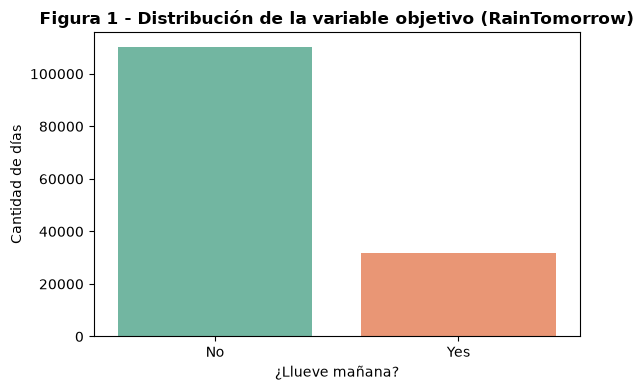

,Frecuencia,Porcentaje (%)
RainTomorrow,,
No,110281,77.58
Yes,31872,22.42


In [3]:
conteo_target = df['RainTomorrow'].value_counts()
pct_target = df['RainTomorrow'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='RainTomorrow', hue='RainTomorrow', palette='Set2', legend=False, ax=ax)
ax.set_title('Figura 1 - Distribución de la variable objetivo (RainTomorrow)', fontweight='bold', fontsize=12)
ax.set_xlabel('¿Llueve mañana?')
ax.set_ylabel('Cantidad de días')
plt.tight_layout()
plt.show()

pd.DataFrame({'Frecuencia': conteo_target, 'Porcentaje (%)': pct_target.round(2)})

**¿Está balanceado el dataset? ¿Por qué importa esta pregunta?**

El dataset está claramente **desbalanceado**: el **77.58%** de los registros corresponde a días en los que no llovió al día siguiente (`No`), frente a solo un **22.42%** de días con lluvia (`Yes`).

Tener un dataset desbalanceado puede producir:
1. **Sesgo en el entrenamiento:** La función de pérdida estándar pondera el error de todas las filas por igual. Como la clase `No` es casi 3.5 veces más frecuente, al modelo le sale "barato" ignorar la clase minoritaria (`Yes`) para minimizar el costo global, corriendo la frontera de decisión y logrando un *Recall* muy bajo en la detección de lluvia. Para corregirlo durante el entrenamiento deberemos aplicar técnicas de balanceo.
2. **Accuracy no confiable:** Con esta distribución, un clasificador trivial que prediga siempre `No` obtendría un *Accuracy* del 77.6% sin haber aprendido a detectar un solo día de lluvia. Por lo tanto, el *Accuracy* por sí solo es engañoso y necesitaremos evaluar los modelos con métricas sensibles a la clase minoritaria como **Recall, Precision, F1-Score y AUC-ROC**.

## 1.3 Estadística descriptiva y comportamiento de las variables

Separamos las variables numéricas de las categóricas para inspeccionar sus rangos de variación, asimetrías y posibles valores fuera de rango.

In [4]:
cols_num = df.select_dtypes(include=[np.number]).columns.tolist()
cols_cat = df.select_dtypes(include=['object', 'string']).columns.drop('RainTomorrow').tolist()

print(f'Variables numéricas ({len(cols_num)}): {cols_num}')
print(f'Variables categóricas ({len(cols_cat)}): {cols_cat}\n')

# Resumen estadístico de las variables numéricas
desc_num = df[cols_num].describe().T
desc_num['mediana'] = df[cols_num].median()
desc_num['skew'] = df[cols_num].skew()
display(desc_num[['count', 'mean', 'mediana', 'std', 'min', '25%', '50%', '75%', 'max', 'skew']].round(2))

# Resumen de las variables categóricas
display(df[cols_cat + ['RainTomorrow']].describe().T)

Variables numéricas (16): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Variables categóricas (5): ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']



,count,mean,mediana,std,min,25%,50%,75%,max,skew
MinTemp,141516.0,12.19,12.0,6.42,-9.7,7.6,12.0,16.8,34.1,0.02
MaxTemp,141831.0,23.23,22.6,7.13,-5.1,17.9,22.6,28.2,49.1,0.22
Rainfall,140747.0,2.35,0.0,8.47,0.0,0.0,0.0,0.8,371.0,9.89
Evaporation,81341.0,5.47,4.8,4.19,0.0,2.6,4.8,7.4,145.0,3.75
Sunshine,74368.0,7.62,8.5,3.78,0.0,4.9,8.5,10.6,14.5,-0.50
WindGustSpeed,132885.0,39.99,38.0,13.63,6.0,31.0,38.0,48.0,135.0,0.87
WindSpeed9am,140805.0,14.03,13.0,8.91,0.0,7.0,13.0,19.0,130.0,0.79
WindSpeed3pm,139524.0,18.64,18.0,8.86,0.0,12.0,18.0,24.0,86.0,0.62
Humidity9am,140379.0,68.82,69.9,19.09,0.0,56.9,69.9,83.1,100.0,-0.48
Humidity3pm,138544.0,51.48,51.9,20.85,0.0,36.5,51.9,65.6,100.0,0.03


,count,unique,top,freq
Location,142153,49,Canberra,3417
WindGustDir,132825,16,W,9775
WindDir9am,132144,16,N,11389
WindDir3pm,138377,16,SE,10662
RainToday,140747,2,No,109296
RainTomorrow,142153,2,No,110281


### Caracterización estadística de las variables

A partir de la exploración de las dimensiones numéricas y categóricas, se identifican los siguientes patrones:

* **Comportamiento de las variables numéricas:**
  * **Simetría en variables térmicas y barométricas:** Las temperaturas (`MinTemp`, `MaxTemp`, `Temp9am`, `Temp3pm`) y las presiones atmosféricas (`Pressure9am`, `Pressure3pm`) presentan coeficientes de asimetría (*skewness*) cercanos a cero ($\vert{}skew\vert{} < 0.25$) y una coincidencia casi exacta entre sus medias y medianas, lo cual refleja distribuciones aproximadamente normales.
  * **Asimetría pronunciada y dispersión:** La variable `Rainfall` presenta un sesgo positivo severo ($skew = 9.89$), con una mediana de $0.0\text{ mm}$ y un valor atípico máximo de $371.0\text{ mm}$, propio de eventos de precipitación extrema concentrados en colas pesadas. Un comportamiento similar se observa en `Evaporation` ($skew = 3.75$).
  * **Heterogeneidad de escalas:** Las magnitudes físicas presentan rangos no comparables (la presión atmosférica promedia $\approx 1016\text{ hPa}$, mientras que la nubosidad varía entre $0$ y $9$ octas), lo que hace indispensable estandarizar las características numéricas en el pipeline de preprocesamiento para no distorsionar los pesos de los modelos lineales ni la convergencia de optimizadores basados en gradientes.

* **Comportamiento de las variables categóricas:**
  * `Location` abarca 49 estaciones meteorológicas distribuidas en Australia (siendo Canberra la de mayor frecuencia con 3417 observaciones).
  * Las direcciones del viento (`WindGustDir`, `WindDir9am`, `WindDir3pm`) cuentan con 16 categorías correspondientes a la rosa de los vientos de 16 rumbos.
  * `RainToday` es una variable dicotómica que refleja la precipitación acumulada en el dia actual ($> 1\text{ mm}$). Junto con la variable objetivo `RainTomorrow`, se codificarán en valores binarios ($0$ y $1$).

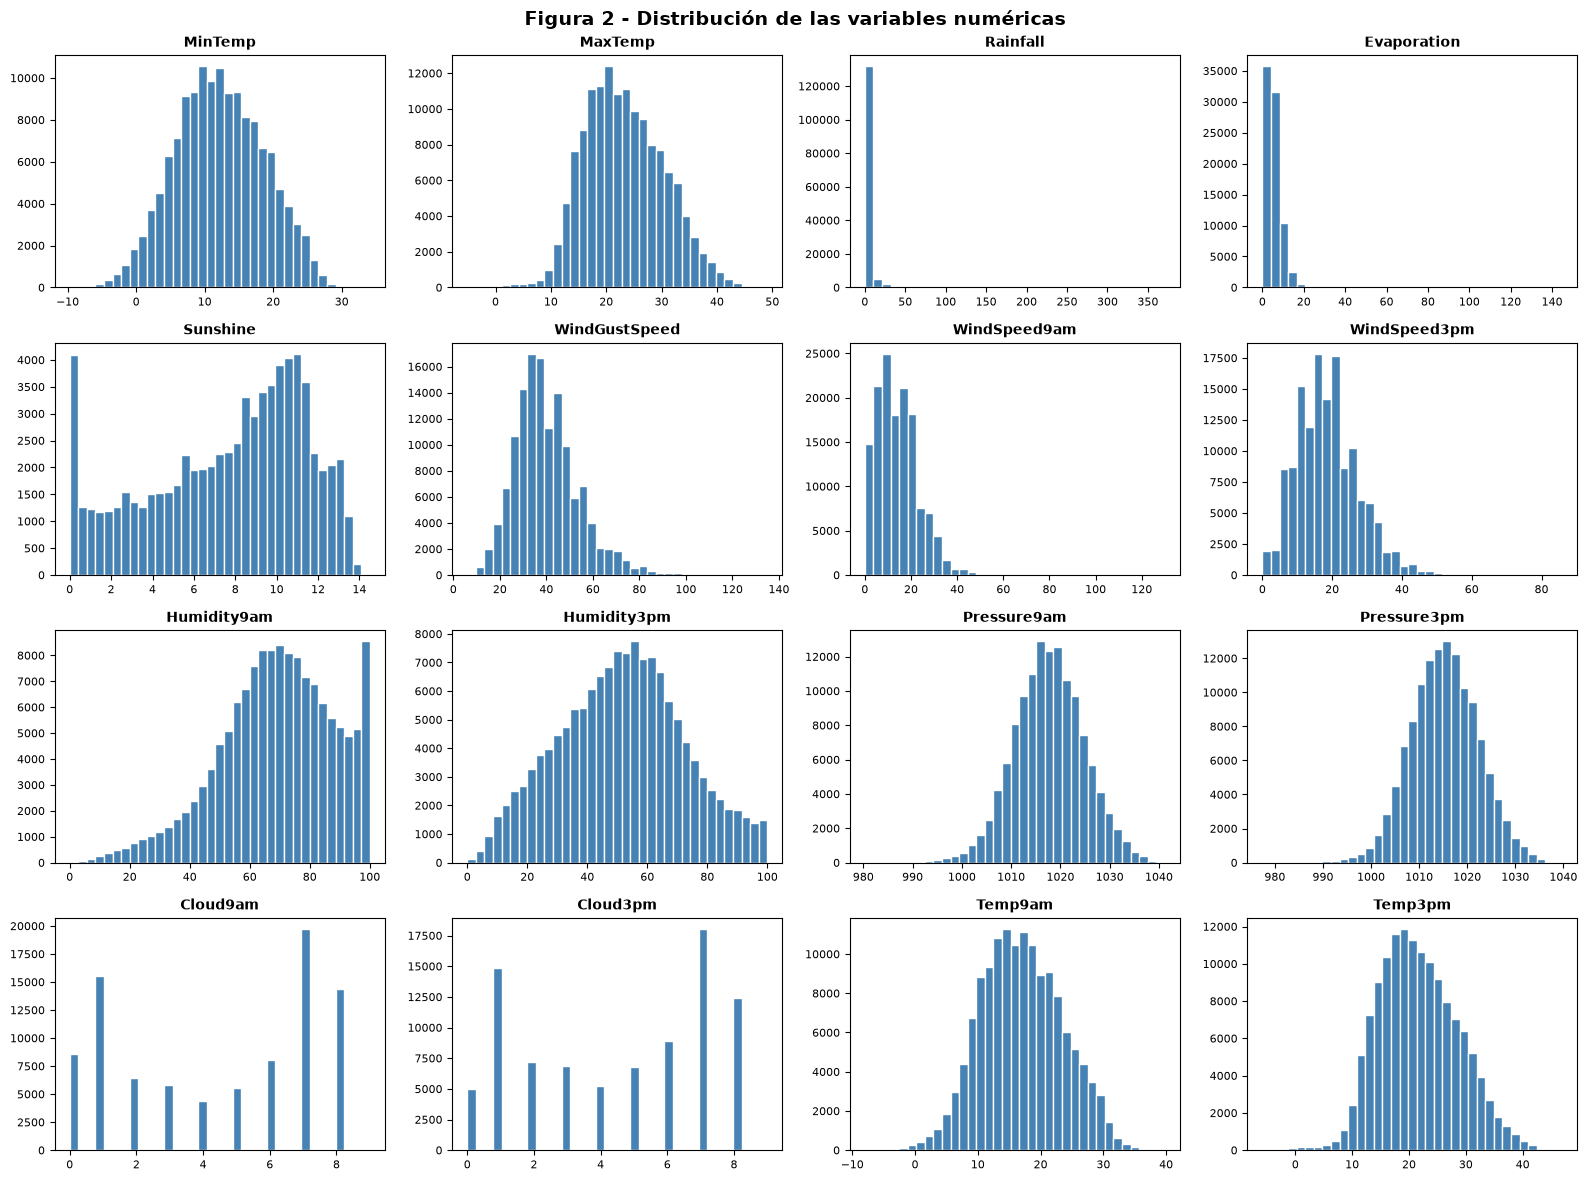

In [5]:
# Histogramas de las variables numéricas
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cols_num):
    axes[i].hist(df[col].dropna(), bins=35, color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].tick_params(labelsize=8)

for j in range(len(cols_num), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Figura 2 - Distribución de las variables numéricas', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

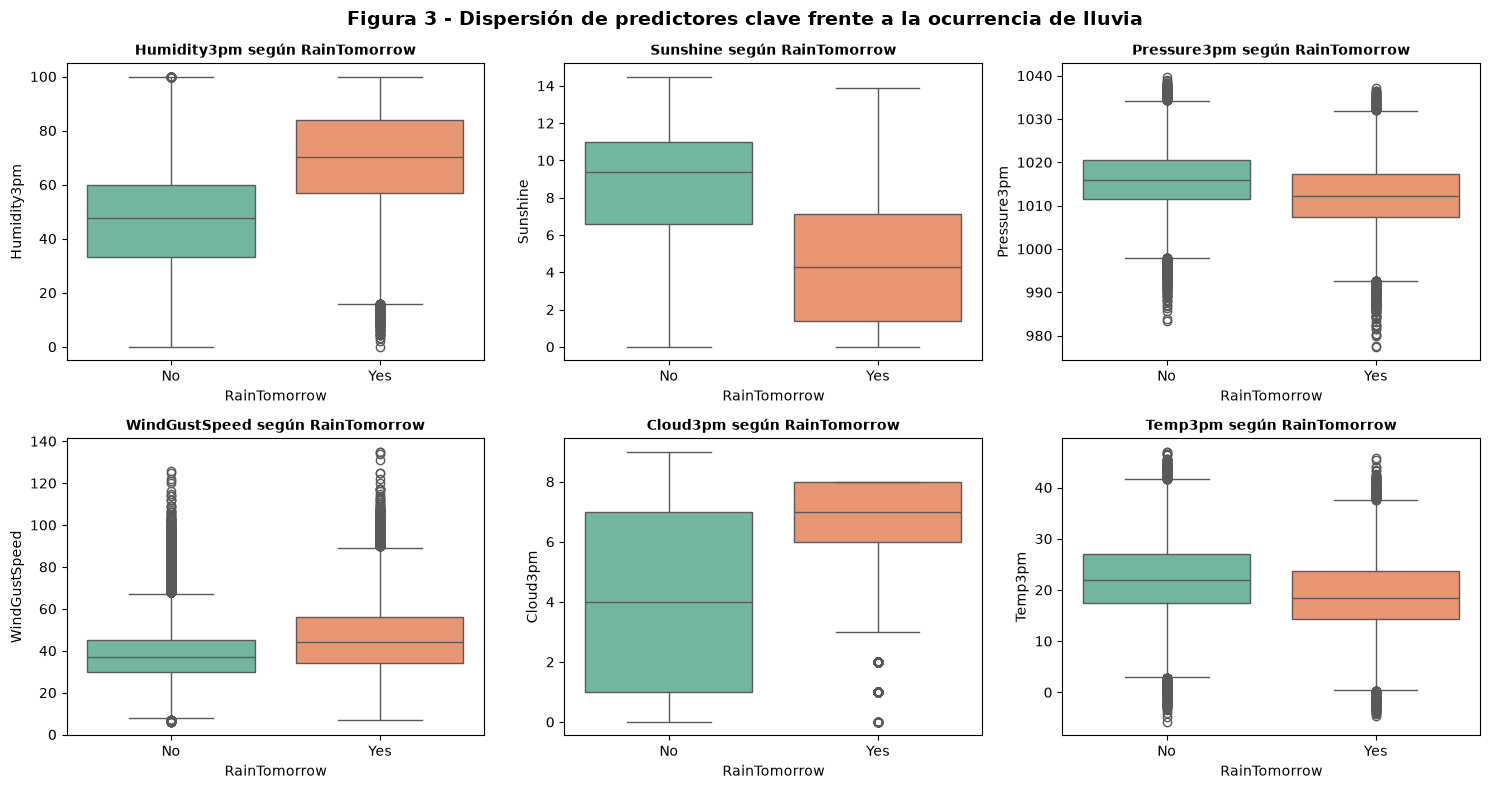

In [6]:
# Boxplots de predictores relevantes discriminados por la variable objetivo
vars_clave = ['Humidity3pm', 'Sunshine', 'Pressure3pm', 'WindGustSpeed', 'Cloud3pm', 'Temp3pm']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(vars_clave):
    sns.boxplot(data=df, x='RainTomorrow', y=col, hue='RainTomorrow', palette='Set2', legend=False, ax=axes[i])
    axes[i].set_title(f'{col} según RainTomorrow', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('RainTomorrow')

plt.suptitle('Figura 3 - Dispersión de predictores clave frente a la ocurrencia de lluvia', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

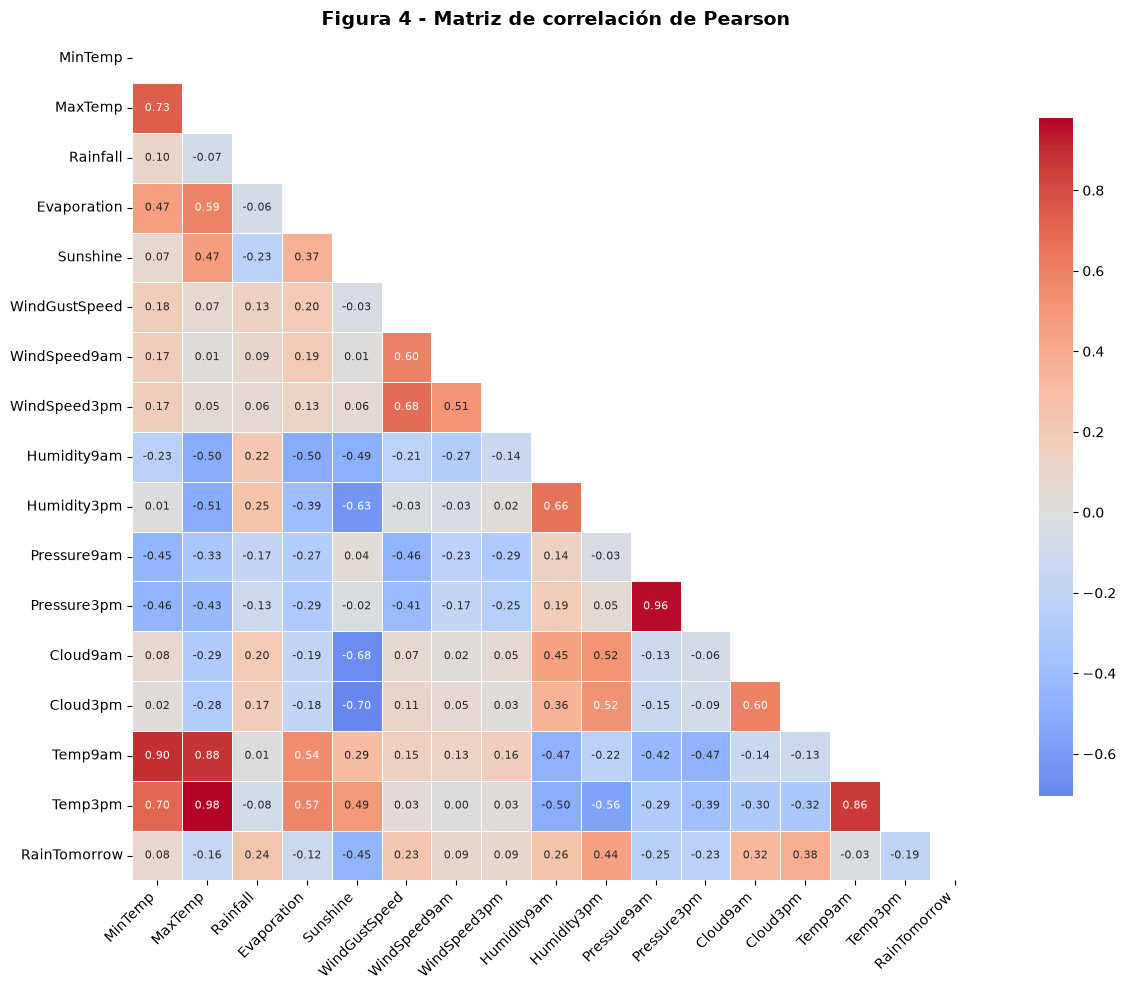

In [7]:
# Matriz de correlación lineal de Pearson (incluyendo target binarizado temporalmente)
df_corr = df[cols_num].copy()
df_corr['RainTomorrow'] = (df['RainTomorrow'] == 'Yes').astype(int)

corr = df_corr.corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, annot_kws={'size': 8}, ax=ax)
ax.set_title('Figura 4 - Matriz de correlación de Pearson', fontweight='bold', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Interpretación de correlaciones y colinealidad:**

* **Relación con la variable objetivo (`RainTomorrow`):** 
  * Los predictores con mayor correlación lineal respecto a la lluvia del día siguiente son la humedad relativa a las 3 pm (`Humidity3pm`, $r \approx 0.45$), la nubosidad a las 3 pm (`Cloud3pm`, $r \approx 0.38$) y las horas de brillo solar (`Sunshine`, correlación inversa $r \approx -0.45$).
  * En contraste, variables como `MinTemp` o `WindSpeed9am` muestran una asociación lineal débil con el evento de lluvia ($\vert{}r\vert{} < 0.15$).

* **Colinealidad entre pares de predictores:**
  * Se observan correlaciones muy elevadas entre pares de mediciones de una misma magnitud física tomadas en horarios distintos o extremos del día: `Temp9am` y `MinTemp` ($r \approx 0.90$), `Temp3pm` y `MaxTemp` ($r \approx 0.98$), así como `Pressure9am` y `Pressure3pm` ($r \approx 0.96$).
  * Esta redundancia de información introduce colinealidad. Si bien modelos regularizados como la Regresión Logística con penalización $L_2$ o redes neuronales pueden convivir con estas dependencias, en fases de selección de características se considerará si es conveniente retener solo una de las lecturas horarias o construir variables agregadas (como la amplitud térmica diaria `MaxTemp - MinTemp` o el gradiente de presión).

## 1.4 Tratamiento de variables cíclicas

### Variable Date
Usamos el dia del año (1 a 366) en lugar del mes ya que aporta mas información que la fecha.
Consideramos que por la cercanía temporal es mas preciso seleccionar el día y no el mes ya que por ejemplo, el 31 de junio se encuentra mas cercano temporalmente al 1 de julio que al 1 de junio.
Codificamos la fecha de forma cíclica y de esta forma observamos un patrón en la estacionalidad de las precipitaciones.

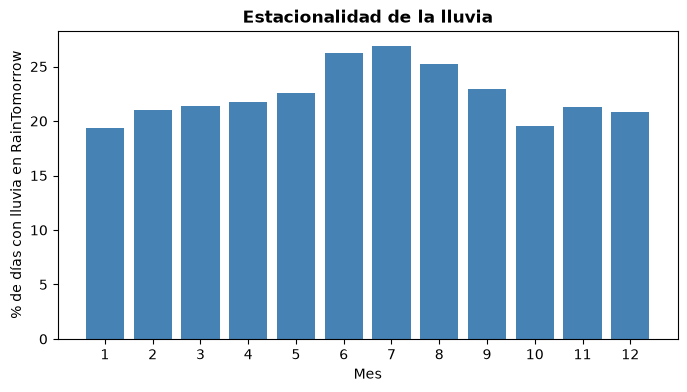

In [8]:
# Proporción de días con lluvia en RainTomorrow
lluvia_mes = (df.assign(Mes=df['Date'].dt.month)
                .groupby('Mes')['RainTomorrow'].apply(lambda s: (s == 'Yes').mean() * 100))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(lluvia_mes.index, lluvia_mes.values, color='steelblue')
ax.set_xticks(range(1, 13))
ax.set_xlabel('Mes'); ax.set_ylabel('% de días con lluvia en RainTomorrow')
ax.set_title('Estacionalidad de la lluvia', fontweight='bold')
plt.show()

**Época del año.** En el análisis vimos que la proporción de días con lluvia cambia a lo largo del año (alrededor de 19% en enero y 27% en julio). Para que el modelo tenga esa información usamos el día del año (de 1 a 366). Para resolverlo ubicamos cada día sobre un círculo y lo representamos con dos columnas: el seno y el coseno del ángulo. Hacen falta las dos columnas porque con una sola, dos fechas diferentes pueden quedar con el mismo valor.

Comprobamos que el clima registrado en un día es influenciado por el del día anterior, si hoy llovió, mañana llueve el 46% de las veces, si no llovió, solo el 15%. Por eso agregamos la información del cambio de presión entre ayer y hoy, ya que una caída de presión suele anticipar lluvia. Solo usamos datos del pasado para evitar fuga de datos. Si en el registro falta el día anterior el valor queda vacío y se imputa más adelante.


In [9]:
# Ordenamos por ciudad y fecha para que los días queden en secuencia dentro de cada ciudad
df = df.sort_values(['Location', 'Date']).reset_index(drop=True)
por_ciudad = df.groupby('Location')

# Tabla auxiliar con la presión de hoy
trayectoria = pd.DataFrame({'Hoy': df['Pressure3pm']})

# Agregamos la presión de 1, 2 y 3 días atrás para la misma ciudad
for dias_atras in [1, 2, 3]:
    # Verificamos que la fila de atrás sea realmente de esa cantidad de días antes (puede haber días faltantes)
    es_dia_correcto = (df['Date'] - por_ciudad['Date'].shift(dias_atras)).dt.days.eq(dias_atras)
    # Nombre de la columna: "Ayer" o "Hace N días"
    nombre = 'Ayer' if dias_atras == 1 else f'Hace {dias_atras} días'
    # Copiamos la presión de ese día. Si el día no está registrado, queda vacío
    trayectoria[nombre] = por_ciudad['Pressure3pm'].shift(dias_atras).where(es_dia_correcto)

# Ordenamos las columnas
trayectoria = trayectoria[['Hace 3 días', 'Hace 2 días', 'Ayer', 'Hoy']]

# Presión promedio de cada día, separando según si llueve o no al día siguiente
promedio = trayectoria.groupby(df['RainTomorrow']).mean().round(2)
promedio

,Hace 3 días,Hace 2 días,Ayer,Hoy
RainTomorrow,,,,
No,1015.23,1015.42,1015.75,1016.11
Yes,1015.37,1014.71,1013.54,1012.30


Los días previos a una lluvia tienen una presión promedio mas baja: la mediana es 1012,2 hPa, contra 1016,0 hPa en los días que no llueve al día siguiente.
Tres días antes, la presión promedio es prácticamente la misma en los dos grupos (1015,2 y 1015,4 hPa). Antes de un día de lluvia la presión baja de forma sostenida hasta 1012,3 hPa, mientras que antes de un día sin lluvia se mantiene estable o sube levemente.
Esto indica que lo que distingue a los dos grupos es su tendencia en los días previos. Para que esta información pueda ser utilizada por el modelo, agregamos el cambio de presión como una columna.

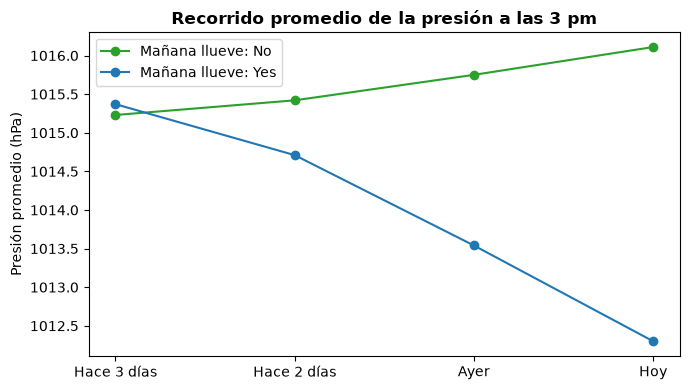

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))

for respuesta, color in [('No', 'tab:green'), ('Yes', 'tab:blue')]:
    ax.plot(promedio.columns, promedio.loc[respuesta], marker='o', color=color,
            label=f'Mañana llueve: {respuesta}')

ax.set_title('Recorrido promedio de la presión a las 3 pm', fontweight='bold')
ax.set_ylabel('Presión promedio (hPa)')
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# Ordenamos las filas por ciudad y por fecha
df = df.sort_values(['Location', 'Date']).reset_index(drop=True)

# --- Época del año ---

# Número de día dentro del año
dia_del_anio = df['Date'].dt.dayofyear

# Convertimos el día en ángulo
angulo_fecha = 2 * np.pi * dia_del_anio / 365.25

# Guardamos la posición de cada día sobre el círculo usando dos columnas
df['Doy_sin'] = np.sin(angulo_fecha)
df['Doy_cos'] = np.cos(angulo_fecha)

# --- Cambio de presión respecto del día anterior ---

por_ciudad = df.groupby('Location')

# Marcamos las filas cuyo registro anterior es del día previo, ya que hay días faltantes
dia_anterior_existe = por_ciudad['Date'].diff().dt.days.eq(1)

# Presión de las 3 pm del día anterior en la misma ciudad (solo se usa para calcular el cambio)
presion_ayer = por_ciudad['Pressure3pm'].shift(1).where(dia_anterior_existe)

# Cambio de presión desde ayer: un valor negativo indica que la presión bajó
df['Pressure3pm_delta'] = df['Pressure3pm'] - presion_ayer

# Porcentaje de valores que quedaron vacíos en la columna nueva
df['Pressure3pm_delta'].isna().mean() * 100

np.float64(10.954394209056439)

### Variables con direcciones de viento

Las columnas `WindGustDir`, `WindDir9am` y `WindDir3pm` indican de dónde viene el viento usando los 16 rumbos de la rosa de los vientos (N, NNE, NE, ..., NNW). Tienen el mismo problema que la fecha: son circulares. Después de NNW viene N otra vez, y esos dos rumbos son vecinos.

Este orden circular tiene que ver con la lluvia: con viento del noroeste (NW, NNW, N) llueve al día siguiente cerca del 28% de las veces, mientras que con viento del este (E, ESE) solo el 17%, y el porcentaje cambia de forma gradual al recorrer la rosa. Si usáramos One-Hot, cada rumbo sería una columna independiente y el modelo no sabría que NNW y N son parecidos. Además, generaríamos 48 columnas.

Por eso a cada rumbo le asignamos un ángulo (N = 0°, y cada rumbo suma 22,5° en sentido horario) y lo representamos con el seno y el coseno. De esta forma quedan 6 columnas en lugar de 48.

Al revisar los faltantes encontramos que muchos de los nulos en las variables que indican la dirección son en realidad días sin viento. Por ejemplo, de los 10.009 nulos de `WindDir9am`, 5.931 son días con velocidad 0. Si no hay viento, no hay dirección, así que no corresponde completarlos con el rumbo más frecuente. A esos días los ubicamos en el centro del círculo (seno = 0 y coseno = 0), que está a la misma distancia de todas las direcciones. Las variables que indican direccion de viento nulas pero que en los indicadores de rafagas y velocidad tienen un valor distinto a 0 quedan vacíos y se completan después de la división con el rumbo más frecuente del conjunto de entrenamiento.

In [12]:
# Los 16 rumbos de la rosa de los vientos, en orden y en sentido horario empezando por el norte
RUMBOS = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE',
          'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']

# Le asignamos a cada rumbo su ángulo en grados: N = 0°, NNE = 22,5°, NE = 45°, etc.
ANGULO_RUMBO = {rumbo: i * 360 / 16 for i, rumbo in enumerate(RUMBOS)}

# Relacionamos cada columna de dirección con la columna de velocidad del mismo momento
PARES_VIENTO = {'WindGustDir': 'WindGustSpeed',
                'WindDir9am': 'WindSpeed9am',
                'WindDir3pm': 'WindSpeed3pm'}


for direccion, velocidad in PARES_VIENTO.items():
    # Reemplazamos el rumbo escrito (por ejemplo 'NW') por su ángulo en grados
    grados = df[direccion].map(ANGULO_RUMBO)
    # Pasamos los grados a radianes, que es la unidad que usan las funciones seno y coseno
    radianes = np.deg2rad(grados)
    # Marcamos los días sin viento (velocidad igual a 0)
    hay_calma = df[velocidad].eq(0)
    # Días con viento: posición del rumbo en el círculo. Días de calma: el centro (0, 0)
    df[f'{direccion}_sin'] = np.where(hay_calma, 0.0, np.sin(radianes))
    df[f'{direccion}_cos'] = np.where(hay_calma, 0.0, np.cos(radianes))


# Eliminamos las columnas originales con los rumbos escritos, que ya fueron reemplazadas
df = df.drop(columns=list(PARES_VIENTO))

# Porcentaje de faltantes reales que quedan para imputar después de la división
df.filter(regex='Wind.*_(sin|cos)').isna().mean().mul(100).round(2)

WindGustDir_sin    6.56
WindGustDir_cos    6.56
WindDir9am_sin     2.87
WindDir9am_cos     2.87
WindDir3pm_sin     2.13
WindDir3pm_cos     2.13
dtype: float64

### Variable Location
Reemplazamos la codificación One-Hot para cada ciudad con la latitud y longitud de cada estación.
De esta manera las estaciones se ubican en el mapa y dos estaciones cercanas tiene valores parecidos. También agrupamos las estaciones por cercanía en 8 regiones de forma tal que se puedan distinguir distintas zonas climáticas, como por ejemplo el norte tropical, el centro desértico o la costa este.

In [13]:
COORDENADAS = {
    'Adelaide': (-34.93, 138.60),      'Albany': (-35.03, 117.88),
    'Albury': (-36.08, 146.92),        'AliceSprings': (-23.70, 133.88),
    'BadgerysCreek': (-33.88, 150.74), 'Ballarat': (-37.56, 143.85),
    'Bendigo': (-36.76, 144.28),       'Brisbane': (-27.47, 153.03),
    'Cairns': (-16.92, 145.77),        'Canberra': (-35.28, 149.13),
    'Cobar': (-31.50, 145.83),         'CoffsHarbour': (-30.30, 153.11),
    'Dartmoor': (-37.92, 141.27),      'Darwin': (-12.46, 130.84),
    'GoldCoast': (-28.02, 153.40),     'Hobart': (-42.88, 147.33),
    'Katherine': (-14.47, 132.26),     'Launceston': (-41.43, 147.14),
    'Melbourne': (-37.81, 144.96),     'MelbourneAirport': (-37.67, 144.84),
    'Mildura': (-34.19, 142.16),       'Moree': (-29.47, 149.84),
    'MountGambier': (-37.83, 140.78),  'MountGinini': (-35.53, 148.77),
    'Newcastle': (-32.93, 151.78),     'Nhil': (-36.33, 141.65),
    'NorahHead': (-33.28, 151.57),     'NorfolkIsland': (-29.04, 167.95),
    'Nuriootpa': (-34.47, 139.00),     'PearceRAAF': (-31.67, 116.02),
    'Penrith': (-33.75, 150.69),       'Perth': (-31.95, 115.86),
    'PerthAirport': (-31.94, 115.97),  'Portland': (-38.34, 141.60),
    'Richmond': (-33.60, 150.75),      'Sale': (-38.10, 147.07),
    'SalmonGums': (-32.98, 121.64),    'Sydney': (-33.87, 151.21),
    'SydneyAirport': (-33.95, 151.18), 'Townsville': (-19.26, 146.82),
    'Tuggeranong': (-35.42, 149.09),   'Uluru': (-25.34, 131.04),
    'WaggaWagga': (-35.12, 147.37),    'Walpole': (-34.98, 116.73),
    'Watsonia': (-37.71, 145.08),      'Williamtown': (-32.80, 151.84),
    'Witchcliffe': (-34.03, 115.10),   'Wollongong': (-34.43, 150.89),
    'Woomera': (-31.20, 136.83),
}
coords = pd.DataFrame.from_dict(COORDENADAS, orient='index', columns=['Lat', 'Lon'])

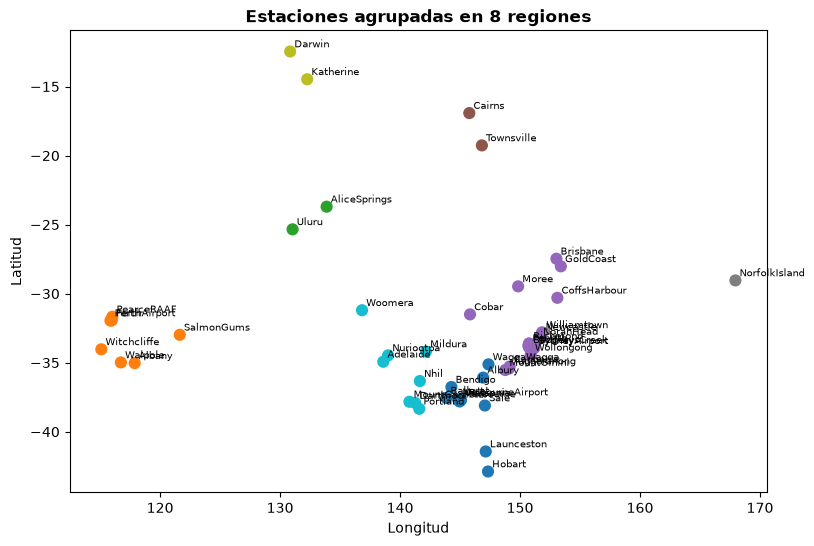

In [14]:
kmeans_region = KMeans(n_clusters=8, n_init=10, random_state=42)
coords['Region'] = kmeans_region.fit_predict(coords[['Lat', 'Lon']])

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(coords['Lon'], coords['Lat'], c=coords['Region'], cmap='tab10', s=60)

for ciudad, fila in coords.iterrows():
    ax.annotate(ciudad, (fila['Lon'], fila['Lat']), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_title('Estaciones agrupadas en 8 regiones', fontweight='bold')
plt.show()

# Cada fila recibe la latitud, longitud y región de su ciudad
df = df.join(coords, on='Location')

## 1.5 Diagnóstico y tratamiento de valores faltantes

Se analiza el volumen y distribución de datos ausentes en cada variable sobre los 142.153 registros con variable objetivo válida.

In [15]:
# Reporte detallado de datos faltantes
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df)) * 100
df_nulos = pd.DataFrame({'Valores Nulos': nulos, 'Porcentaje (%)': pct_nulos})
df_nulos = df_nulos[df_nulos['Valores Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False)
display(df_nulos.round(2))

,Valores Nulos,Porcentaje (%)
Sunshine,67785,47.68
Evaporation,60812,42.78
Cloud3pm,57076,40.15
Cloud9am,53641,37.73
Pressure3pm_delta,15572,10.95
Pressure9am,14010,9.86
Pressure3pm,13977,9.83
WindGustDir_sin,9328,6.56
WindGustDir_cos,9328,6.56
WindGustSpeed,9268,6.52


### Criterios de tratamiento de valores faltantes

De acuerdo con el análisis del reporte, los datos faltantes se estructuran en tres grupos diferenciados:

1. **Variables con ausencia crítica ($>35\%$):** `Sunshine` ($47.68\%$), `Evaporation` ($42.78\%$), `Cloud3pm` ($40.15\%$) y `Cloud9am` ($37.73\%$) presentan una gran cantidad de nulos.
2. **Variables con ausencia moderada ($5\%$ a $10\%$):** Presiones atmosféricas (`Pressure9am`, `Pressure3pm`) y ráfagas máximas de viento (`WindGustDir`, `WindGustSpeed`).
3. **Variables con ausencia reducida ($<3\%$):** Temperaturas, mediciones de viento a las 9 am/3 pm, humedad y `RainToday`.

**Metodología de imputacion**
Para evitar la pérdida de más del 60% del dataset, se preservan las observaciones y se aplicará **imputación**:
- Temperaturas (MinTemp, MaxTemp, Temp9am, Temp3pm): Imputamos con la temperatura del día anterior en la misma ciudad porque la temperatura cambia poco de un día al día siguiente. Para aquellos nulos que no se conoce la temperatura del día anterior se completan con la mediana de train luego del split.
- Vientos 
    - Direcciones (WindGustDir, WindDir9am, WindDir3pm): los nulos se ubican en el centro del circulo (0, 0) al crear las variables de seno y coseno.
    - Velocidades (WindGustSpeed, WindSpeed9am, WindSpeed3pm): se imputa con la mediana.
- Presión, Humedad, Nubosidad, Horas de sol, evaporación, lluvia del día: se imputan con la mediana calculada de train luego del split.

In [16]:
# Ordenamos por ciudad y fecha para que el registro anterior sea el día previo de la misma ciudad
df = df.sort_values(['Location', 'Date']).reset_index(drop=True)
por_ciudad = df.groupby('Location')
dia_anterior_existe = por_ciudad['Date'].diff().dt.days.eq(1)

cols_temp = ['MinTemp', 'MaxTemp', 'Temp9am', 'Temp3pm']
nulos_antes = df[cols_temp].isna().sum()

for col in cols_temp:
    # Marcamos el faltante antes de completarlo, para que el modelo sepa que el valor fue imputado
    df[f'{col}_falta'] = df[col].isna().astype(int)
    # Temperatura del día anterior en la misma ciudad
    temp_ayer = por_ciudad[col].shift(1).where(dia_anterior_existe)
    df[col] = df[col].fillna(temp_ayer)

pd.DataFrame({'Nulos antes': nulos_antes,
              'Completados con ayer': nulos_antes - df[cols_temp].isna().sum(),
              'Quedan para la mediana': df[cols_temp].isna().sum()})

,Nulos antes,Completados con ayer,Quedan para la mediana
MinTemp,637,316,321
MaxTemp,322,224,98
Temp9am,904,445,459
Temp3pm,2725,473,2252


## 1.6 Train - Test Split

Dividimos los datos por fecha utilizando los primeros 70% de los días para train, el 10% siguiente para validación y el ultimo 20% para test. De esta forma el modelo se entrena con el pasado y se evalua con días posteriores.
Los cortes quedaron en:
- Hasta el 12/01/2015 para train
- Hasta el 09/11/2015 para validacion.

In [17]:
# Convertimos Yes en 1 y No en 0
df['RainToday'] = df['RainToday'].map({'Yes': 1, 'No': 0})
y = df['RainTomorrow'].map({'Yes': 1, 'No': 0})
X = df.drop(columns=['RainTomorrow'])

# 70% train, 10% validación, 20% test ordenado cronologicamente
corte_val = X['Date'].quantile(0.7)
corte_test = X['Date'].quantile(0.8)
train = X['Date'] < corte_val
val = (X['Date'] >= corte_val) & (X['Date'] < corte_test)
test = X['Date'] >= corte_test

X_train, y_train = X[train].drop(columns='Date'), y[train]
X_val, y_val = X[val].drop(columns='Date'), y[val]
X_test, y_test = X[test].drop(columns='Date'), y[test]

print(f'Cortes: {corte_val.date()} y {corte_test.date()}')
print(f'Filas -> train: {len(X_train)} | validación: {len(X_val)} | test: {len(X_test)}')
print(f'Lluvia -> train: {y_train.mean():.1%} | validación: {y_val.mean():.1%} | test: {y_test.mean():.1%}')

Cortes: 2015-01-12 y 2015-11-09
Filas -> train: 99499 | validación: 14202 | test: 28452
Lluvia -> train: 22.6% | validación: 21.7% | test: 22.3%


## 1.7 Codificación, imputacion y escalado

Luego de la división aplicamos 3 transformaciones. 
- Región: usamos One-Hot con get_dummies sobre las 8 regiones. Luego reordenamos validación y test con las columnas de train.
- Valores faltantes: completamos los nulos según los criterios definidos en el punto 1.5.
- Estandarizacion: llevamos todas las columnas a media 0 y desvío 1.

In [18]:
# Eliminamos location ya que queda representada por Lat y Lon
X_train = X_train.drop(columns='Location')
X_val = X_val.drop(columns='Location')
X_test = X_test.drop(columns='Location')

# Una columna 0/1 por region
X_train = pd.get_dummies(X_train, columns=['Region'], drop_first=True, dtype=int)
X_val = pd.get_dummies(X_val, columns=['Region'], drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=['Region'], drop_first=True, dtype=int)

# alineamos las columnas de validacion y test con las de train
X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [19]:
# Columnas con al menos un nulo en train
cols_con_nulos = X_train.columns[X_train.isna().any()]
cols_viento = X_train.filter(regex='^Wind.*_(sin|cos)$').columns
cols_mediana = cols_con_nulos.drop(cols_viento)

# Medianas calculadas solo con train
medianas = X_train[cols_mediana].median()

# Indicadores faltantes
cols_indicador = [c for c in cols_con_nulos
                  if not c.endswith('_cos') and f'{c}_falta' not in X_train.columns]

# Tabla con el tratamiento de cada columna
resumen_nulos = pd.DataFrame({
    'Nulos en train (%)': X_train[cols_con_nulos].isna().mean().mul(100).round(2),
    'Tratamiento': ['Constante 0 (centro del círculo)' if c in cols_viento else 'Mediana de train'
                    for c in cols_con_nulos],
    'Valor imputado': [0 if c in cols_viento else medianas[c] for c in cols_con_nulos],
}).sort_values('Nulos en train (%)', ascending=False)
display(resumen_nulos)

for datos in (X_train, X_val, X_test):
    # Columna que marca si el dato faltaba
    for col in cols_indicador:
        datos[f'{col}_falta'] = datos[col].isna().astype(int)
    # Viento con nulo queda en el centro del círculo
    datos[cols_viento] = datos[cols_viento].fillna(0)
    # el resto de las columnas con nulos se imputan con la mediana
    datos[cols_mediana] = datos[cols_mediana].fillna(medianas)

print('Nulos -> train:', X_train.isna().sum().sum(),
      '| validación:', X_val.isna().sum().sum(),
      '| test:', X_test.isna().sum().sum())

,Nulos en train (%),Tratamiento,Valor imputado
Sunshine,41.17,Mediana de train,8.4
Evaporation,37.55,Mediana de train,4.6
Cloud3pm,37.15,Mediana de train,5.0
Cloud9am,36.15,Mediana de train,5.0
Pressure3pm_delta,10.62,Mediana de train,-0.2
Pressure9am,9.45,Mediana de train,1017.5
Pressure3pm,9.41,Mediana de train,1015.1
WindGustDir_sin,7.01,Constante 0 (centro del círculo),0.0
WindGustDir_cos,7.01,Constante 0 (centro del círculo),0.0
WindGustSpeed,6.97,Mediana de train,38.0


Nulos -> train: 0 | validación: 0 | test: 0


### Estandarización

Dado que las variables tienen escalas distintas (presion al rededor de 1015 hPa, nubosidad de 0 a 9), estandarizamos para obtener columnas con media 0 y desvio 1. 

In [20]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

(99499, 56) (14202, 56) (28452, 56)


# 2. Regresión logística

## 2.1 Entrenamiento

Entrenamos 2 modelos, uno aplicando balanceo de clases con class_weight='balanced' para darle mas peso a los días con lluvia (22490 filas) frente a los dias que no llueve (77010 filas) y otro modelo sin aplicar balanceo de clases.

In [21]:
modelo_rl = LogisticRegression(max_iter=2000)
modelo_rl.fit(X_train_scaled, y_train)

# Probabilidad de lluvia y predicción con el umbral por defecto (0.5)
prob_train = modelo_rl.predict_proba(X_train_scaled)[:, 1]
prob_val = modelo_rl.predict_proba(X_val_scaled)[:, 1]
y_pred_val = modelo_rl.predict(X_val_scaled)

In [22]:
# class_weight='balanced' compensa el desbalance entre días con y sin lluvia
modelo_rl_balanced = LogisticRegression(max_iter=2000, class_weight='balanced')
modelo_rl_balanced.fit(X_train_scaled, y_train)

# Probabilidad de lluvia y predicción con el umbral por defecto (0.5)
prob_train_balanced = modelo_rl_balanced.predict_proba(X_train_scaled)[:, 1]
prob_val_balanced = modelo_rl_balanced.predict_proba(X_val_scaled)[:, 1]
y_pred_val_balanced = modelo_rl_balanced.predict(X_val_scaled)

## 2.2 Métricas

In [23]:
# precision, recall y F1 para "No llueve" y "Llueve" sin balanceo de clases
print(classification_report(y_val, y_pred_val, target_names=['No llueve', 'Llueve']))

# Comparación entre train y validación para evaluar el fitting
def calcular_metricas(y_real, prob, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    return {'Accuracy': accuracy_score(y_real, pred),
            'Precision': precision_score(y_real, pred),
            'Recall': recall_score(y_real, pred),
            'F1': f1_score(y_real, pred),
            'ROC-AUC': roc_auc_score(y_real, prob)}

pd.DataFrame({'Train': calcular_metricas(y_train, prob_train),
              'Validación': calcular_metricas(y_val, prob_val)}).round(3)

              precision    recall  f1-score   support

   No llueve       0.87      0.95      0.91     11119
      Llueve       0.73      0.47      0.57      3083

    accuracy                           0.85     14202
   macro avg       0.80      0.71      0.74     14202
weighted avg       0.84      0.85      0.83     14202



,Train,Validación
Accuracy,0.848,0.847
Precision,0.727,0.730
Recall,0.521,0.470
F1,0.607,0.572
ROC-AUC,0.874,0.869


In [24]:
# precision, recall y F1 para "No llueve" y "Llueve" con balanceo de clases
print(classification_report(y_val, y_pred_val_balanced, target_names=['No llueve', 'Llueve']))

pd.DataFrame({'Train': calcular_metricas(y_train, prob_train_balanced),
              'Validación': calcular_metricas(y_val, prob_val_balanced)}).round(3)

              precision    recall  f1-score   support

   No llueve       0.92      0.82      0.87     11119
      Llueve       0.53      0.75      0.62      3083

    accuracy                           0.80     14202
   macro avg       0.73      0.78      0.74     14202
weighted avg       0.84      0.80      0.81     14202



,Train,Validación
Accuracy,0.794,0.801
Precision,0.529,0.530
Recall,0.782,0.747
F1,0.631,0.620
ROC-AUC,0.875,0.871


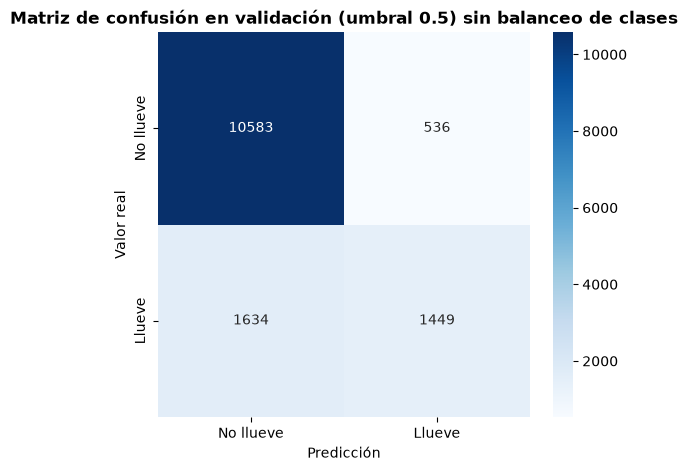

In [25]:
# matriz de confusión para el modelo sin balanceo de clases
matriz = confusion_matrix(y_val, y_pred_val)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No llueve', 'Llueve'], yticklabels=['No llueve', 'Llueve'], ax=ax)
ax.set_xlabel('Predicción')
ax.set_ylabel('Valor real')
ax.set_title('Matriz de confusión en validación (umbral 0.5) sin balanceo de clases', fontweight='bold')
plt.show()

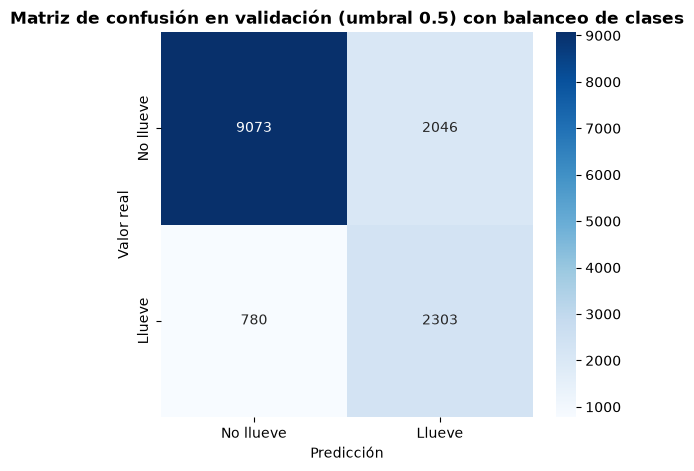

In [26]:
# matriz de confusión para el modelo con balanceo de clases
matriz = confusion_matrix(y_val, y_pred_val_balanced)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No llueve', 'Llueve'], yticklabels=['No llueve', 'Llueve'], ax=ax)
ax.set_xlabel('Predicción')
ax.set_ylabel('Valor real')
ax.set_title('Matriz de confusión en validación (umbral 0.5) con balanceo de clases', fontweight='bold')
plt.show()

### Análisis de Falsos Positivos (FP) y Falsos Negativos (FN)

En el contexto de la predicción de lluvia:
*   **Falso Positivo (FP):** El modelo predice lluvia, pero el día resulta sin lluvia. Esto representa una falsa alarma.
*   **Falso Negativo (FN):** El modelo predice que no lloverá, pero finalmente sí llueve. Esto implica no detectar un evento de lluvia.

Al analizar las matrices de confusión en validación (umbral 0.5):
*   **Modelo sin balancear:** Presenta 536 falsos positivos y 1634 falsos negativos. El modelo es conservador al predecir lluvia, priorizando no equivocarse cuando dice que lloverá (alta precisión, bajo recall).
*   **Modelo balanceado:** Presenta 2046 falsos positivos y 780 falsos negativos. Al compensar el desbalance, el modelo se vuelve más sensible. Reduce a la mitad los falsos negativos (detecta mucha más lluvia), a costa de cuadruplicar las falsas alarmas (falsos positivos).

**Costo relativo:** En general, un Falso Negativo es más costoso (no prevenir inundaciones o arruinar eventos) que un Falso Positivo (llevar paraguas sin necesidad). Por lo tanto, el modelo balanceado, al minimizar los falsos negativos, resulta más útil en la práctica.

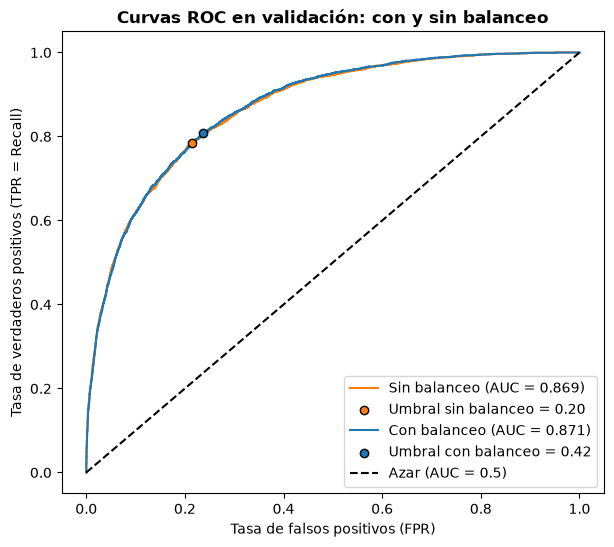

In [27]:
# Curva ROC en validación de cada modelo
fpr_sin, tpr_sin, umbrales_sin = roc_curve(y_val, prob_val)
fpr, tpr, umbrales = roc_curve(y_val, prob_val_balanced)

# criterio de Youden: el umbral donde TPR - FPR es máximo
indice_sin = np.argmax(tpr_sin - fpr_sin)
indice_mejor = np.argmax(tpr - fpr)
umbral_elegido = umbrales[indice_mejor]

fig, ax = plt.subplots(figsize=(7, 6))

# Modelo sin balanceo
ax.plot(fpr_sin, tpr_sin, color='tab:orange',
        label=f'Sin balanceo (AUC = {auc(fpr_sin, tpr_sin):.3f})')
ax.scatter(fpr_sin[indice_sin], tpr_sin[indice_sin], color='tab:orange', edgecolor='black', zorder=3,
           label=f'Umbral sin balanceo = {umbrales_sin[indice_sin]:.2f}')

# Modelo con balanceo
ax.plot(fpr, tpr, color='tab:blue',
        label=f'Con balanceo (AUC = {auc(fpr, tpr):.3f})')
ax.scatter(fpr[indice_mejor], tpr[indice_mejor], color='tab:blue', edgecolor='black', zorder=3,
           label=f'Umbral con balanceo = {umbral_elegido:.2f}')

ax.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.5)')
ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR = Recall)')
ax.set_title('Curvas ROC en validación: con y sin balanceo', fontweight='bold')
ax.legend(loc='lower right')
plt.show()

En el grafico de las curvas ROC de ambos modelos podemos observar que casi se superponen. El balanceo de clases no hace que el modelo separe mejor los días con y sin lluvia sino que ordena los dias casi igual que el modelo sin balanceo pero le asigna a cada uno una probabilidad de lluvia mas alta.

In [28]:
prob_test = modelo_rl_balanced.predict_proba(X_test_scaled)[:, 1]
pd.DataFrame({'Umbral 0.50': calcular_metricas(y_test, prob_test, 0.5),
              f'Umbral elegido ({umbral_elegido:.2f})': calcular_metricas(y_test, prob_test, umbral_elegido)}).round(3)

,Umbral 0.50,Umbral elegido (0.42)
Accuracy,0.787,0.746
Precision,0.515,0.461
Recall,0.772,0.825
F1,0.618,0.592
ROC-AUC,0.861,0.861


### Análisis de Resultados y Ajuste del Umbral de Decisión

A partir de las métricas obtenidas, se concluye lo siguiente:

1. Generalización del modelo: Se ha conseguido un buen fitting, ya que el modelo generaliza correctamente sin presentar signos de overfitting, dado que manteniene métricas estables entre el conjunto de entrenamiento y el de validación (ROC-AUC 0.87). 
2. Impacto del desbalance de clases: Al utilizar el umbral por defecto (0.5), el modelo se inclina hacia la clase mayoritaria (`No llueve`), logrando un Accuracy del 80% aproximadamente, pero con un recall bajo en la clase minoritaria, lo que se traduce en muchos falsos negativos (días de lluvia no detectados).
3. Optimización mediante el Criterio de Youden: A través del análisis de la Curva ROC, se calculó el punto óptimo que maximiza la diferencia entre la Tasa de Verdaderos Positivos (TPR) y la Tasa de Falsos Positivos (FPR). Este cálculo sugirió reducir el umbral de decisión a 0.45. 
4. Trade-off : Al aplicar el umbral de 0.42, el Recall sobre la clase de lluvia asciende por encima del 0.80, logrando que el modelo detecte más días lluviosos. Debido a esto, la precisión cae levemente (aumentan los falsos positivos). Dado el contexto del problema (es meteorológicamente preferible advertir sobre una lluvia que no ocurre, a no advertir sobre una tormenta que sí sucede), este ajuste de umbral resulta estratégicamente favorable.

# 3. Modelo base

Para saber si la regresión logistica aporta algo la comparamos con dos modelos simples que no aprenden de los datos:
- Clase mayoritaria: siempre predice "no llueve".
- Persistencia: predice que mañana pasa lo mismo que hoy (RainTomorrow = RainToday).

In [29]:
# predice la clase mayoritaria
modelo_base = DummyClassifier(strategy='most_frequent')
modelo_base.fit(X_train_scaled, y_train)
prob_base = modelo_base.predict_proba(X_test_scaled)[:, 1]

# la lluvia de mañana es igual a la de hoy (usamos X_test sin escalar, donde RainToday es 0/1)
prob_persistencia = X_test['RainToday']

pd.DataFrame({'Clase mayoritaria': calcular_metricas(y_test, prob_base),
              'Persistencia': calcular_metricas(y_test, prob_persistencia),
              'Reg. logística (0.5)': calcular_metricas(y_test, prob_test, 0.5),
              f'Reg. logística ({umbral_elegido:.2f})': calcular_metricas(y_test, prob_test, umbral_elegido)}).round(3)

c:\Proyectos_tuia\TUIA_AA1_2026\TP1\venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Clase mayoritaria,Persistencia,Reg. logística (0.5),Reg. logística (0.42)
Accuracy,0.777,0.753,0.787,0.746
Precision,0.000,0.446,0.515,0.461
Recall,0.000,0.441,0.772,0.825
F1,0.000,0.443,0.618,0.592
ROC-AUC,0.500,0.642,0.861,0.861


La clase mayoritaria tiene un accuracy de 0.77 pero recall 0, por lo tanto nunca detecta un dia de lluvia.
La persistencia detecta 0.441 de los dias de lluvia.
La regresión logistica supera los dos modelos base en todas las métricas menos en accuracy, la cual esta inflada por el desbalance.

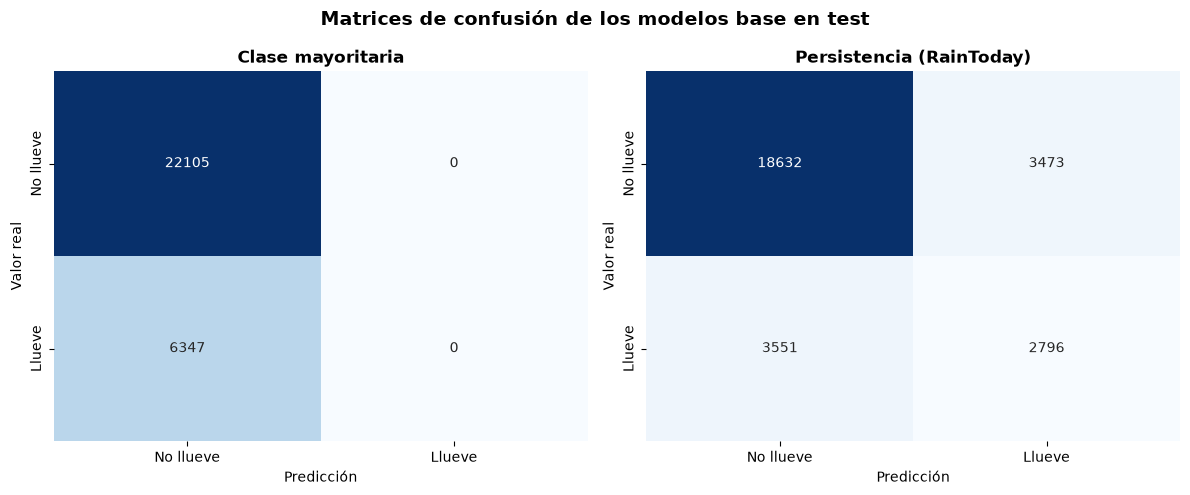

In [30]:
# Predicciones en test de los modelos base
pred_base = (prob_base >= 0.5).astype(int)          # siempre 0: nunca predice lluvia
pred_persistencia = prob_persistencia.astype(int)   # RainTomorrow = RainToday

predicciones_base = {'Clase mayoritaria': pred_base,
                     'Persistencia (RainToday)': pred_persistencia}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, pred) in zip(axes, predicciones_base.items()):
    # labels=[0, 1] asegura la matriz de 2x2 aunque el modelo nunca prediga lluvia
    matriz = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No llueve', 'Llueve'], yticklabels=['No llueve', 'Llueve'], ax=ax)
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Valor real')
    ax.set_title(nombre, fontweight='bold')

fig.suptitle('Matrices de confusión de los modelos base en test', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Análisis de las Matrices de Confusión de los Modelos Base


1. **Modelo de Clase Mayoritaria (Dummy Classifier):**
   * Al predecir sistemáticamente "No llueve", logra acertar los 22.105 días sin lluvia (Verdaderos Negativos), pero falla en la totalidad de los eventos de precipitación, acumulando 6.347 Falsos Negativos. 
   * Aunque este modelo alcanza un ~77% de aciertos globales, su Recall es exactamente del 0%, haciéndolo completamente inútil para la prevención y alerta meteorológica.

2. **Modelo de Persistencia (RainTomorrow = RainToday):**
   * Asumir por inercia que el clima de mañana será idéntico al de hoy resulta ser una heurística mucho mejor, logrando detectar correctamente 2.796 días de lluvia (Verdaderos Positivos).
   * Sin embargo, comete errores elevados y simétricos: 3.551 Falsos Negativos (comienza a llover tras un día sin lluvia) y 3.473 Falsos Positivos (el día se despeja tras un día lluvioso). Esto indica que, si bien la autocorrelación del clima es fuerte, es insuficiente por sí sola como predictor confiable.

**Conclusión:**
Las métricas y matrices confirman que nuestra Regresión Logística (especialmente la versión con pesos balanceados y umbral ajustado mediante el estadístico de Youden) supera holgadamente a ambos modelos base. Esto demuestra que el algoritmo efectivamente logró capturar e integrar relaciones multivariables complejas (presión, humedad, nubosidad, vientos) para anticipar los cambios de clima, en lugar de apoyarse en meras probabilidades estáticas o inercias del día previo.

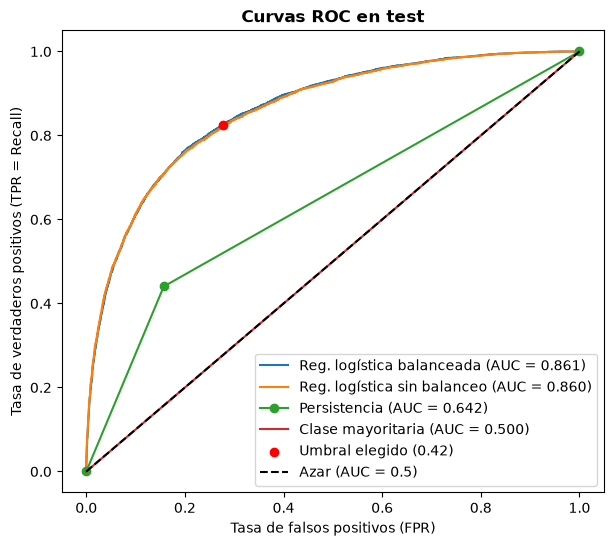

In [31]:
# Probabilidades en test de cada modelo
modelos_roc = {'Reg. logística balanceada': prob_test,
               'Reg. logística sin balanceo': modelo_rl.predict_proba(X_test_scaled)[:, 1],
               'Persistencia': prob_persistencia,
               'Clase mayoritaria': prob_base}

fig, ax = plt.subplots(figsize=(7, 6))
for nombre, prob in modelos_roc.items():
    fpr_m, tpr_m, _ = roc_curve(y_test, prob)
    ax.plot(fpr_m, tpr_m, marker='o' if nombre == 'Persistencia' else None,
            label=f'{nombre} (AUC = {auc(fpr_m, tpr_m):.3f})')

# Punto de la regresión logística con el umbral elegido en validación
tn, fp, fn, tp = confusion_matrix(y_test, (prob_test >= umbral_elegido).astype(int)).ravel()
ax.scatter(fp / (fp + tn), tp / (tp + fn), color='red', zorder=3,
           label=f'Umbral elegido ({umbral_elegido:.2f})')

ax.plot([0, 1], [0, 1], 'k--', label='Azar (AUC = 0.5)')
ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR = Recall)')
ax.set_title('Curvas ROC en test', fontweight='bold')
ax.legend(loc='lower right')
plt.show()

### Análisis Integrado de Curvas ROC y Desempeño Global

1. **Superioridad de los Modelos Entrenados:** 
   Ambas variantes de Regresión Logística (con y sin balanceo de clases) exhiben un Área Bajo la Curva (ROC-AUC) de 0.865 aproximadamente, distanciándose significativamente de la línea de azar. El hecho de que sus curvas se superpongan casi por completo demuestra que el parámetro `class_weight='balanced'` no altera la capacidad intrínseca del modelo para ordenar las probabilidades (el poder de discriminación entre clases se mantiene), sino que simplemente desplaza la distribución de dichas probabilidades para favorecer la predicción de la clase minoritaria bajo un umbral estático.

2. **Justificación del Umbral Óptimo (0.42):** 
   El punto rojo sobre la curva de la regresión logística marca el umbral de 0.42, calculado previamente mediante el estadístico de Youden en validación. Visualmente, se comprueba que este punto se ubica en el "codo" de la curva, logrando la máxima aproximación a la esquina superior izquierda (0, 1). Esto representa el mejor balance teórico entre maximizar la detección de días lluviosos (TPR) y contener la tasa de falsas alarmas (FPR).

3. **Limitaciones Estructurales de los Modelos Base:**
   * **Persistencia (AUC = 0.642):** Su gráfica no es una curva suave sino un vértice geométrico. Esto ocurre porque es un modelo determinista que no emite probabilidades continuas, sino predicciones duras discretas (0 o 1). Aunque supera al azar aprovechando la autocorrelación temporal del clima, su capacidad de discriminación es marcadamente inferior a la regresión logística.
   * **Clase Mayoritaria (AUC = 0.500):** Al predecir siempre "No llueve", carece por completo de capacidad discriminativa, ubicándose exactamente sobre la diagonal de adivinanza aleatoria.

**Conclusión Final de la Etapa de Modelado Base:**
El pipeline de preprocesamiento sobre las variables y el entrenamiento de la Regresión Logística permitieron que el modelo identifique patrones reales en los datos. Las métricas en el conjunto de test confirman que el clasificador generaliza de manera correcta y supera con amplitud a los modelos base, demostrando ser una herramienta mucho más útil y confiable que depender de enfoques simples como la clase mayoritaria o la persistencia del día anterior.


# 4. Optimización de la seleccion de hiperparámetros
Optimizamos 3 hiperparámetros:
- c: es la inversa de la regularización. Un c chico penaliza más los coeficientes, esto genera un modelo más simple y con menos riesgo de overfiting. Por el contrario un c grande deja los coeficientes más libres.
- Tipo de penalizacion (l1_ratio): 0 es ridge el cual achica todos los coeficientes y 1 es lasso el cual puede dejar algunos coeficientes en 0 y asi descartar variables.
- class_weight: None o 'balanced'.

### Busqueda
Usamos grid search porque son pocos hiperparámetros y pocas combinaciones.

### Validación cruzada
Usamos TimeSeriesSplit ya que ordena train por fecha y en cada fold entrena con el pasado y valida con el período siguiente.

### Métrica
Elegimos F1 de la clase "Llueve" para decidir porque combina precision y recall y es adecuado con clases desbalanceadas. No usamos ROC-AUC porque casi no cambia con class_weight entonces no ayudaría a elegir ese hiperparámetro.

In [32]:
# TimeSeriesSplit necesita las filas en orden cronológico (train está ordenado por ciudad)
orden_fecha = df.loc[X_train_scaled.index, 'Date'].sort_values(kind='stable').index

# Combinaciones a probar
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100],
              'l1_ratio': [0, 1],                 # 0 = Ridge (L2), 1 = Lasso (L1)
              'class_weight': [None, 'balanced']}

# entrena con el pasado y valida con el periodo siguiente
grid = GridSearchCV(LogisticRegression(solver='liblinear', max_iter=2000), param_grid,
                    cv=TimeSeriesSplit(n_splits=5),
                    scoring=['f1', 'roc_auc', 'recall', 'precision'], refit='f1', n_jobs=-1)
grid.fit(X_train_scaled.loc[orden_fecha], y_train.loc[orden_fecha])

print('Mejores hiperparámetros:', grid.best_params_)
print(f'F1 promedio en validación cruzada: {grid.best_score_:.4f}')

Mejores hiperparámetros: {'C': 100, 'class_weight': 'balanced', 'l1_ratio': 0}
F1 promedio en validación cruzada: 0.6274


In [33]:
# Promedio de cada métrica en los 5 folds ordenado por F1
resultados = pd.DataFrame(grid.cv_results_)
cols = ['param_C', 'param_l1_ratio', 'param_class_weight', 'mean_test_f1', 'std_test_f1',
        'mean_test_roc_auc', 'mean_test_recall', 'mean_test_precision']
resultados[cols].sort_values('mean_test_f1', ascending=False).round(4)

,param_C,param_l1_ratio,param_class_weight,mean_test_f1,std_test_f1,mean_test_roc_auc,mean_test_recall,mean_test_precision
22,100.000,0,balanced,0.6274,0.0106,0.8717,0.7744,0.5274
23,100.000,1,balanced,0.6273,0.0106,0.8717,0.7744,0.5274
18,10.000,0,balanced,0.6273,0.0106,0.8717,0.7744,0.5274
14,1.000,0,balanced,0.6273,0.0106,0.8717,0.7744,0.5274
19,10.000,1,balanced,0.6273,0.0106,0.8717,0.7743,0.5274
15,1.000,1,balanced,0.6272,0.0103,0.8717,0.7742,0.5273
10,0.100,0,balanced,0.6271,0.0103,0.8717,0.7742,0.5272
11,0.100,1,balanced,0.6270,0.0104,0.8717,0.7741,0.5271
6,0.010,0,balanced,0.6259,0.0104,0.8715,0.7755,0.5249
7,0.010,1,balanced,0.6247,0.0103,0.8705,0.7744,0.5237


In [34]:
prob_val_grid = grid.best_estimator_.predict_proba(X_val_scaled)[:, 1]

# Umbral de Youden en validación
fpr_g, tpr_g, umbrales_g = roc_curve(y_val, prob_val_grid)
umbral_grid = umbrales_g[np.argmax(tpr_g - fpr_g)]

pd.DataFrame({f'Punto 2 ({umbral_elegido:.2f})': calcular_metricas(y_val, prob_val_balanced, umbral_elegido),
              f'Grid search ({umbral_grid:.2f})': calcular_metricas(y_val, prob_val_grid, umbral_grid)}).round(3)

,Punto 2 (0.42),Grid search (0.43)
Accuracy,0.774,0.776
Precision,0.487,0.490
Recall,0.808,0.804
F1,0.608,0.609
ROC-AUC,0.871,0.871


# 5. Explicabilidad del modelo

Para interpretar las decisiones del modelo de Regresión Logística optimizado, aplicamos la biblioteca SHAP (*SHapley Additive exPlanations*). Dado que tratamos con un modelo lineal, empleamos `LinearExplainer`.

Los valores SHAP se calculan en escala *log-odds*. Para el análisis, utilizamos una muestra de fondo de 1.000 observaciones del conjunto de entrenamiento y explicamos las predicciones sobre 2.000 observaciones del conjunto de prueba.

In [35]:
modelo_final = grid.best_estimator_

X_fondo = X_train_scaled.sample(1000, random_state=42)
X_explicar = X_test_scaled.sample(2000, random_state=42)

explainer = shap.LinearExplainer(modelo_final, X_fondo)
sv_escalado = explainer(X_explicar)

sv = shap.Explanation(values=sv_escalado.values,
                        base_values=sv_escalado.base_values,
                        data=X_test.loc[X_explicar.index].values,
                        feature_names=list(X_test.columns))

valor_base = sv.base_values[0]
print(f'Valor base: {valor_base:.3f} log-odds -> probabilidad {1 / (1 + np.exp(-valor_base)):.1f}')

Background dataset has 1000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1000 when initializing the masker.


Valor base: -0.811 log-odds -> probabilidad 0.3


In [36]:
coefs = pd.Series(modelo_final.coef_[0], index=X_train_scaled.columns)

shap_manual = (X_explicar - X_fondo.mean()) * coefs

print('SHAP coincide con coeficiente x valor: ', np.allclose(sv.values, shap_manual.values))

importancia = pd.DataFrame({'Coeficiente': coefs,
                            'Importancia SHAP':
                            np.abs(sv.values).mean(axis=0)})
importancia.sort_values('Importancia SHAP', ascending=False).round(3).head(15)

SHAP coincide con coeficiente x valor:  False


,Coeficiente,Importancia SHAP
Humidity3pm,1.123,0.866
Pressure3pm,-0.672,0.535
WindGustSpeed,0.632,0.476
Pressure9am,0.313,0.247
Cloud3pm,0.324,0.217
WindGustDir_sin_falta,0.376,0.193
WindGustSpeed_falta,-0.373,0.192
Cloud3pm_falta,-0.177,0.182
RainToday,0.236,0.180
Doy_cos,-0.177,0.165


### 5.1 Importancia global de las características

La magnitud absoluta de los valores SHAP permite cuantificar el peso de cada variable en la frontera de decisión. 

El modelo depende fuertemente de tres variables estructurales: la humedad relativa a las 3 pm (`Humidity3pm`), la presión atmosférica (`Pressure3pm`) y la velocidad de las ráfagas máximas de viento (`WindGustSpeed`). Esta jerarquía predictiva se mantiene incluso al agrupar las variables derivadas (coordenadas, regiones y codificaciones cíclicas), confirmando que las condiciones termodinámicas de la tarde son los mejores predictores del clima del día siguiente.

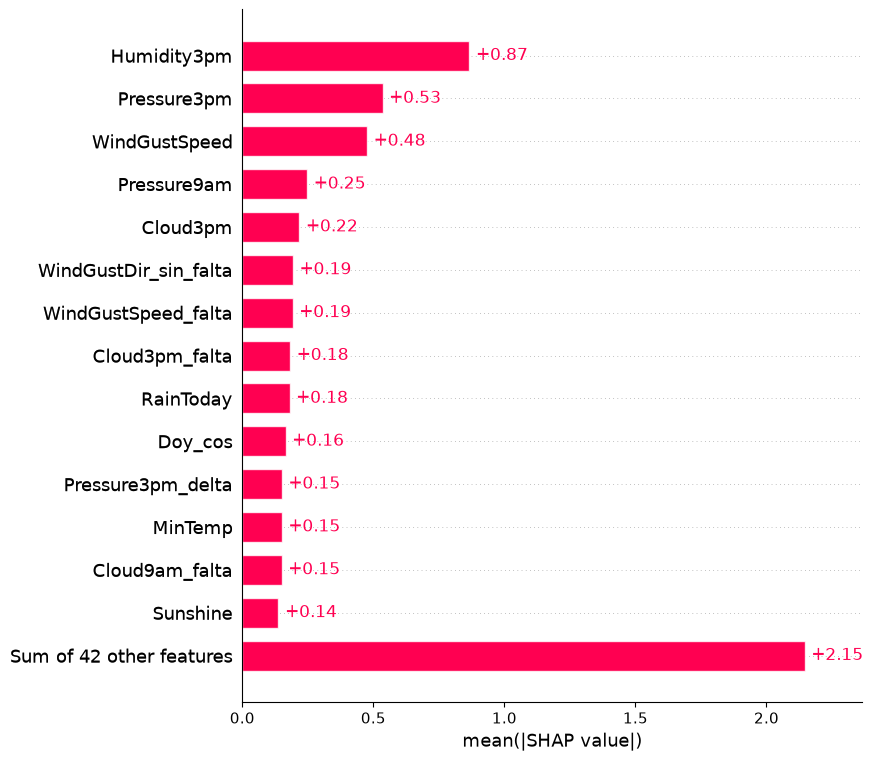

In [38]:
shap.plots.bar(sv, max_display=15)

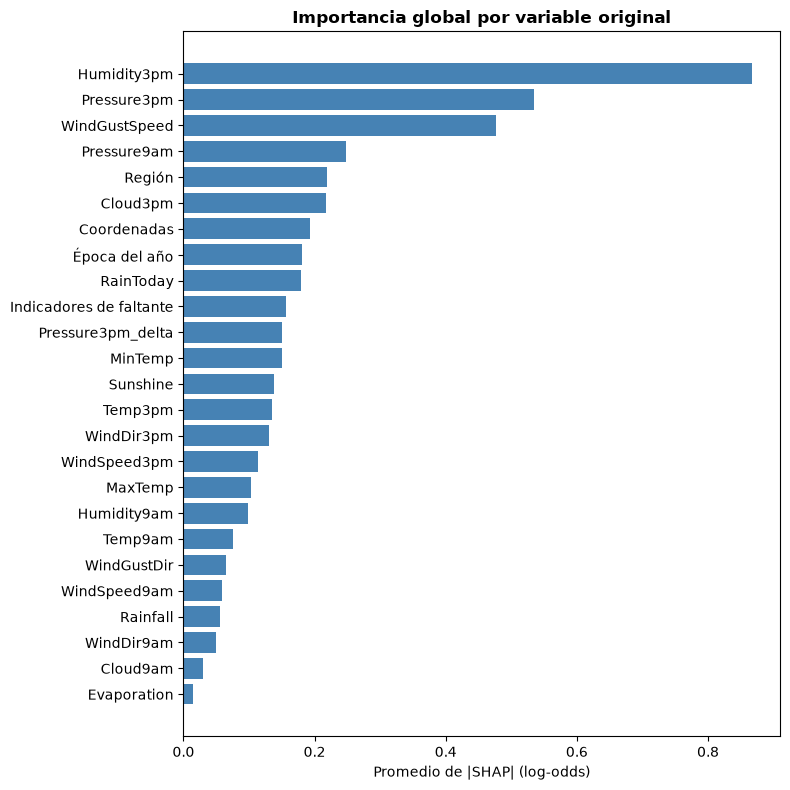

In [39]:
shap_df = pd.DataFrame(sv.values, columns=sv.feature_names)
cols = pd.Index(shap_df.columns).astype(str)

# Grupo de cada columna: seno/coseno, regiones, coordenadas y faltantes se juntan en una sola variable
grupos = np.select([cols.str.endswith('_falta'), cols.str.startswith('Region_'),
                    cols.isin(['Lat', 'Lon']), cols.str.startswith('Doy_')],
                   ['Indicadores de faltante', 'Región', 'Coordenadas', 'Época del año'],
                   default=cols.str.replace(r'_(sin|cos)$', '', regex=True))

# Por la aditividad podemos sumar los SHAP de un grupo en cada día y después promediar el valor absoluto
importancia_grupo = shap_df.T.groupby(grupos).sum().T.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(importancia_grupo.index, importancia_grupo.values, color='steelblue')
ax.set_xlabel('Promedio de |SHAP| (log-odds)')
ax.set_title('Importancia global por variable original', fontweight='bold')
plt.tight_layout()
plt.show()

### 5.2 Dirección del efecto y colinealidad

El gráfico de enjambre (*beeswarm*) desglosa cómo los distintos valores de cada característica empujan la predicción. Los puntos rojos indican valores altos de la variable, mientras que los azules representan valores bajos.

*   **Variables promotoras de lluvia:** Niveles elevados de humedad, nubosidad y ráfagas de viento presentan valores SHAP positivos (desplazan la predicción hacia "Llueve"). 
*   **Variables inhibidoras:** Altas presiones atmosféricas y mayor cantidad de horas de sol penalizan fuertemente la probabilidad de precipitación. Una caída abrupta de presión (`Pressure3pm_delta` negativo) también incrementa la probabilidad de lluvia.

Los gráficos de dispersión exhiben una linealidad perfecta. Este comportamiento es matemáticamente inherente a la Regresión Logística, donde el efecto marginal de cada característica es estrictamente constante. Asimismo, el efecto opuesto que adoptan `Pressure9am` y `Pressure3pm` en el modelo evidencia cómo el algoritmo regularizado (mediante penalización) reparte el peso de dos variables fuertemente colineales (r aproximadamente de 0.96) para evitar redundancia de información.

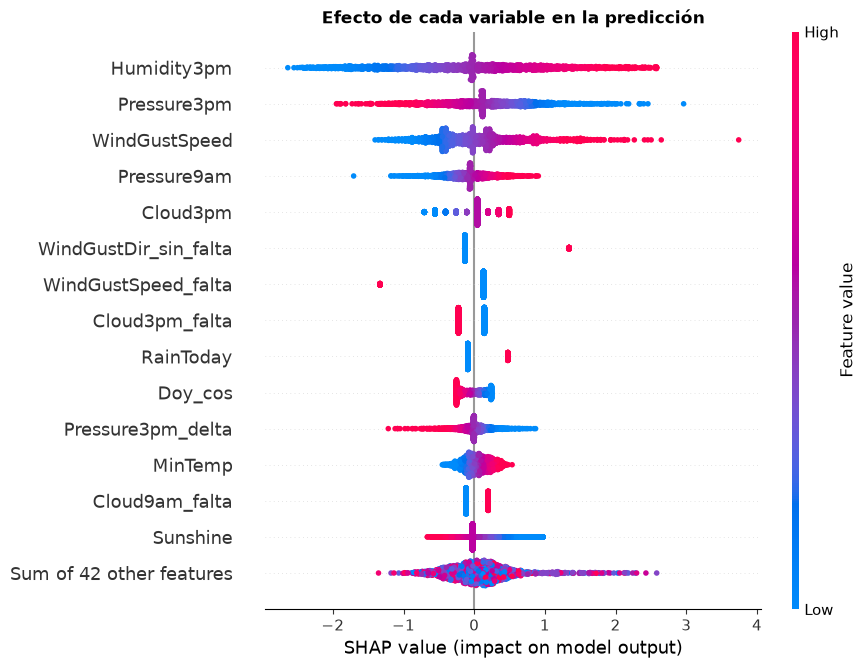

In [40]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title('Efecto de cada variable en la predicción', fontweight='bold')
plt.show()

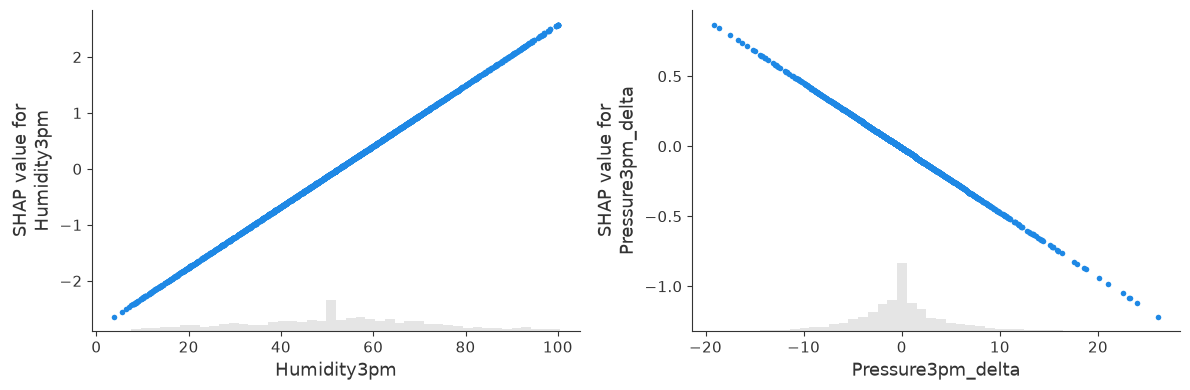

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shap.plots.scatter(sv[:, 'Humidity3pm'], ax=axes[0], show=False)
shap.plots.scatter(sv[:, 'Pressure3pm_delta'], ax=axes[1], show=False)
plt.tight_layout()
plt.show()

### 5.3 Explicabilidad local: Análisis de casos particulares

La explicabilidad local permite diseccionar predicciones individuales mediante gráficos de cascada (*waterfall plots*), partiendo del valor base esperado de la muestra y sumando o restando el aporte (en *log-odds*) de cada característica particular de ese día.

Se seleccionan tres casos extremos del conjunto de prueba para evaluar el comportamiento interno del modelo ante aciertos y errores de alta confianza.

In [44]:
prob_test_final = modelo_final.predict_proba(X_test_scaled)[:, 1]
pred_test_final = prob_test_final >= umbral_grid
prob = pd.Series(prob_test_final, index=X_test.index)

# Verdadero positivo con la probabilidad más alta, falso negativo más seguro y falso positivo más seguro
casos = {'Verdadero positivo': prob[(y_test == 1) & pred_test_final].idxmax(),
         'Falso negativo': prob[(y_test == 1) & ~pred_test_final].idxmin(),
         'Falso positivo': prob[(y_test == 0) & pred_test_final].idxmax()}

pd.DataFrame({nombre: {'Ciudad': df.loc[i, 'Location'], 'Fecha': df.loc[i, 'Date'].date(),
                       'Prob. de lluvia': round(prob[i], 3), 'Llovió': 'Sí' if y_test[i] == 1 else 'No'}
              for nombre, i in casos.items()})

,Verdadero positivo,Falso negativo,Falso positivo
Ciudad,Sydney,Williamtown,CoffsHarbour
Fecha,2016-06-05,2016-06-12,2016-06-05
Prob. de lluvia,1.0,0.033,1.0
Llovió,Sí,Sí,No


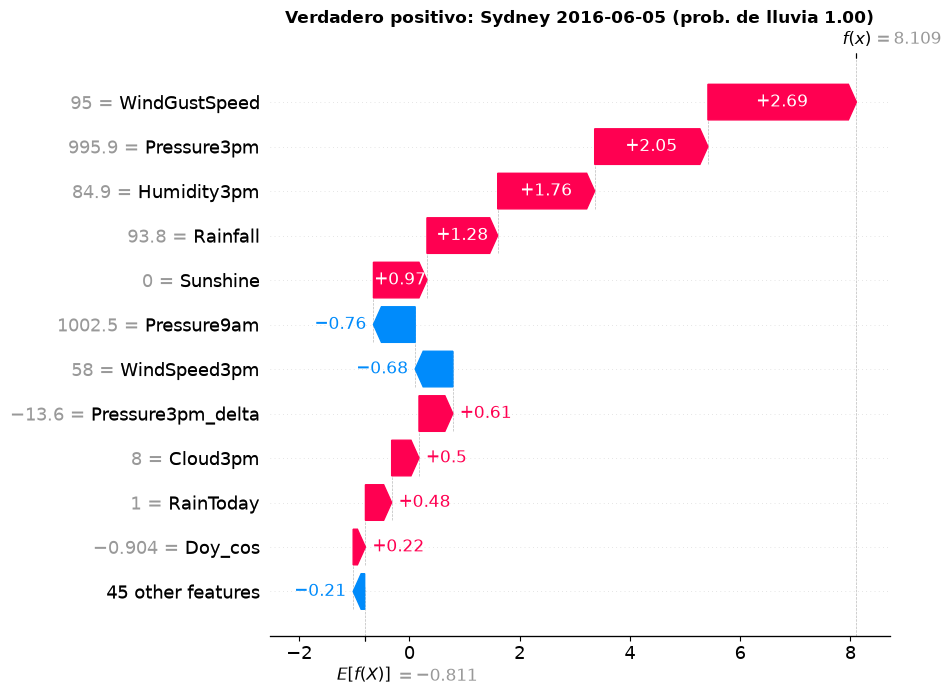

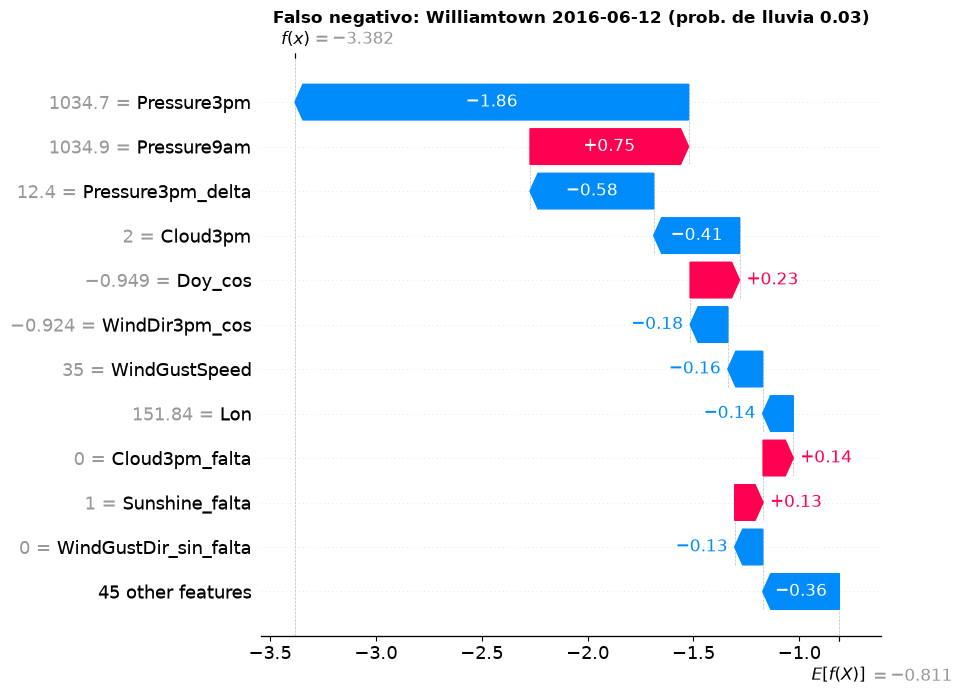

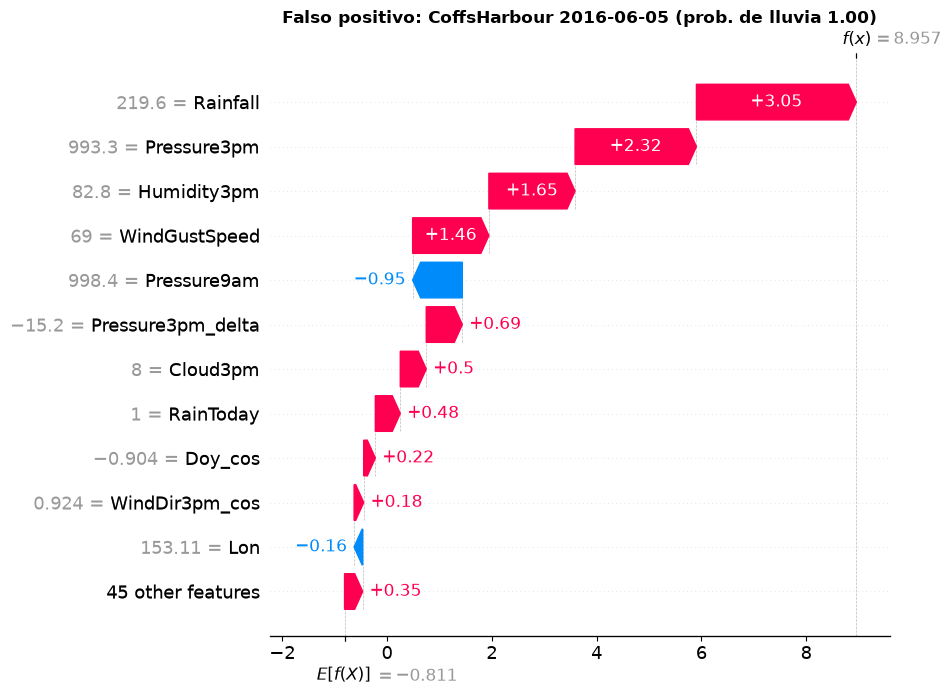

In [45]:
for nombre, i in casos.items():
    sv_dia = explainer(X_test_scaled.loc[[i]])
    sv_dia = shap.Explanation(values=sv_dia.values[0], base_values=sv_dia.base_values[0],
                              data=X_test.loc[i].values, feature_names=list(X_test.columns))
    shap.plots.waterfall(sv_dia, max_display=12, show=False)
    plt.title(f"{nombre}: {df.loc[i, 'Location']} {df.loc[i, 'Date'].date()} "
              f"(prob. de lluvia {prob[i]:.2f})", fontweight='bold')
    plt.show()

**Interpretación de las predicciones extremas:**

*   **Verdadero Positivo (Sydney, 2016-06-05):** El modelo predijo lluvia con una probabilidad de aproximadamente 1.00. El impacto combinado de ráfagas severas (`WindGustSpeed` aportando +2.69), presión baja y humedad elevada empujaron el *log-odds* final por encima de $8.1$.
*   **Falso Negativo (Williamtown, 2016-06-12):** Un error grave (probabilidad predicha 0.03 frente a lluvia real). El fallo se explica casi enteramente por un registro de presión atmosférica inusualmente alto a las 3 pm (1034.7  hPa), el cual introdujo un castigo de $-1.86$ *log-odds*, forzando al modelo a clasificar el día como seco e ignorando indicadores menores.
*   **Falso Positivo (Coffs Harbour, 2016-06-05):** Falsa alarma extrema. La precipitación masiva del día en curso (`Rainfall` = 219.6 mm) aportó +3.05 *log-odds*, un peso tan atípico que saturó la predicción. El modelo asume que tras semejante temporal continuará lloviendo, pero el evento se disipó al día siguiente.